# X identification - neural-network model of the drone's motion along x

**Advanced task 2: land the drone at a different position (move along x).** Same job as
`4_identification_yaw.ipynb`, for the horizontal motion instead of the rotation.

`data_generation/generate_x_data.m` drove the motors through a **mixer** whose pairing was found by its
probe (black box: only the 4 commands in and the 18 outputs are used):

```
u_i = u_T + S_X(i) * u_x        S_X = [-1 0 1 0]     u_T : collective thrust (altitude policy)
                                                    u_x : differential command on motors 1 and 3
```

Speeding motor 3 up and motor 1 down **tilts** the drone (pitch `theta`), and the tilted thrust pushes
it along x. The chain is longer than for the yaw:

```
(u_x, u_T) --> [ unknown dynamics ] --> w_dot_y --> wy --> theta --> ax --> vx --> x
                ^                            integrals   ^          integrals
           identified (network)                    tilted thrust:
                                                   ax = f(theta, az)  (physics, checked here)
```

Two differences with the yaw:

* the `theta` **output** is unusable (in `UAV_model.slx` its noise has a huge, seed-dependent
  variance), so the tilt is **recovered by integrating `wy`**, which is clean;
* the excitation is made of **quadruplets** `+v, -v, [hold], -v, +v`: with no restoring torque a
  doublet leaves the drone tilted, the quadruplet brings `wy` and `theta` back to 0. Each block holds
  a quadruplet and its mirror, so that the speed `vx` is given back too.

| section | question |
|---|---|
| 1-2 | load the data and **validate** it (outliers, pure pitch, kinematics, tilt from `wy`) |
| 3 | **order** of the dynamics (pulse response), input delay |
| 4 | **physics** around the model: restoring torque? damping? drag? the law `ax = f(theta, az)` |
| 5 | **least-squares** models (linear, polynomial gain, physical tanh model) |
| 6 | the **neural network**, validated in free run |
| 7 | what matters for control: the **position** predicted over the duration of a move |
| 8 | **coupling**: does the motion along x disturb the altitude and the heading? |
| 9 | save the model for the RL environment |

## 0. Setup

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import joblib
from scipy.io import loadmat
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

Ts          = 0.05
G           = 9.81
DATA        = os.path.join('..', 'data', 'x')
N_TRAIN_MAX = 1_000_000     # samples given to the network
N_REST      = 40            # samples at rest at the start of every experiment (u = 0)
SEED        = 0

plt.rcParams['figure.figsize'] = (11, 3.2); plt.rcParams['axes.grid'] = True
np.set_printoptions(suppress=True, precision=4)
os.makedirs('figures', exist_ok=True); os.makedirs('models', exist_ok=True)

## 1. Load the data

One row per experiment, one column per sample (Ts = 0.05 s), as in the course's dataset. Everything
is read from `x_dataset.mat` (all 18 outputs; the CSVs next to it hold the main signals in the
course's layout). The mixer `S_X` and the noise level come with the data.

Signals used: the commands `u_T`, `u_x`; the pitch acceleration `w_dot_y` (identified), the pitch rate
`wy` (integrated into the tilt), `ax`, `vx`, `x` (kinematics and predicted position), `az` (tilted
thrust and coupling), `phi`, `wx` (pure-pitch check), `w_dot_z` (coupling with the yaw).

In [2]:
d = loadmat(os.path.join(DATA, 'x_dataset.mat'))
NAMES = [n[0] for n in d['NAMES'].ravel()]
YALL = d['YALL'].astype(float)
sig = lambda name: YALL[:, :, NAMES.index(name)]
UT, UX = d['UT'].astype(float), d['UX'].astype(float)
W, WY, AX, VX, X = sig('w_dot_y'), sig('wy'), sig('ax'), sig('vx'), sig('x')
AZ, PHI, WX, WDZ, THETA_OUT = sig('az'), sig('phi'), sig('wx'), sig('w_dot_z'), sig('theta')
S_X, G_NOISE = d['S_X'].ravel(), float(d['G_NOISE'].item())
del YALL

n_exp, n_t = UT.shape
t = np.arange(n_t) * Ts
print(f'{n_exp} experiments x {n_t} samples ({n_t * Ts:.0f} s each), mixer S_X = {S_X}, g_noise = {G_NOISE}')
print(f'u_T in [{UT[:, N_REST:].min():.2f}, {UT.max():.2f}]   u_x in [{UX.min():.4f}, {UX.max():.4f}]')
print(f'w_dot_y in [{W.min():.1f}, {W.max():.1f}] rad/s^2   wy in [{WY.min():.2f}, {WY.max():.2f}] rad/s')
print(f'theta OUTPUT: std {THETA_OUT[:, N_REST:].std():.2f} rad  -> noise, not used')

400 experiments x 600 samples (30 s each), mixer S_X = [-1. -0.  1. -0.], g_noise = 0.01
u_T in [0.20, 0.70]   u_x in [-0.0499, 0.0499]
w_dot_y in [-5.9, 5.9] rad/s^2   wy in [-0.83, 0.83] rad/s
theta OUTPUT: std 2.90 rad  -> noise, not used


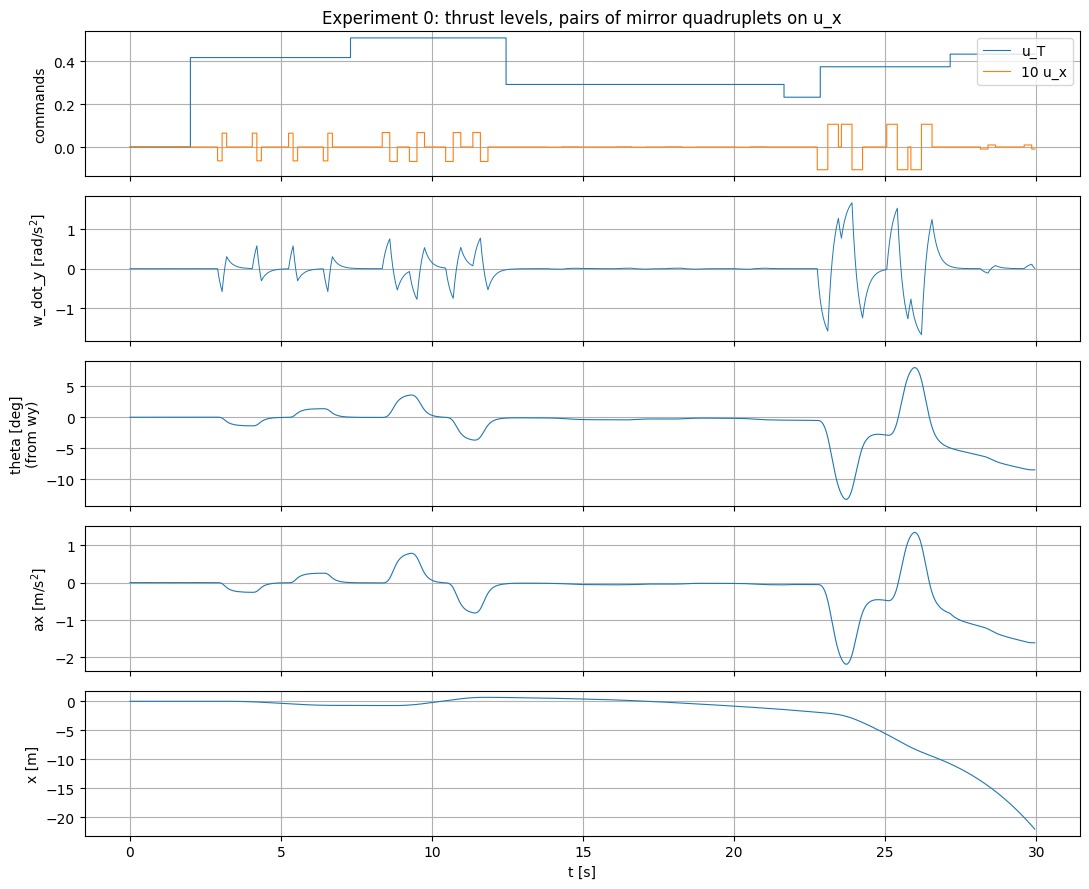

In [3]:
def tilt(wy):
    """theta recovered from the pitch rate (trapezoid, theta = 0 at rest)."""
    th = np.zeros_like(wy)
    th[..., 1:] = np.cumsum(Ts * (wy[..., :-1] + wy[..., 1:]) / 2, axis=-1)
    return th

TH = tilt(WY)

i = 0
fig, ax = plt.subplots(5, 1, sharex=True, figsize=(11, 9))
ax[0].step(t, UT[i], where='post', lw=.8, label='u_T'); ax[0].step(t, 10 * UX[i], where='post', lw=.8, label='10 u_x')
ax[0].legend(loc='upper right'); ax[0].set_ylabel('commands')
ax[1].plot(t, W[i], lw=.7);  ax[1].set_ylabel('w_dot_y [rad/s$^2$]')
ax[2].plot(t, np.degrees(TH[i]), lw=.8); ax[2].set_ylabel('theta [deg]\n(from wy)')
ax[3].plot(t, AX[i], lw=.8); ax[3].set_ylabel('ax [m/s$^2$]')
ax[4].plot(t, X[i], lw=.8); ax[4].set_ylabel('x [m]'); ax[4].set_xlabel('t [s]')
ax[0].set_title(f'Experiment {i}: thrust levels, pairs of mirror quadruplets on u_x')
plt.tight_layout(); plt.show()

## 2. Validate the dataset

Physics-based checks, then drop whole experiments that fail:

* **rest check**: the first 40 samples are at `u = 0`: `w_dot_y` must be 0 and `az` must be $-g$;
* **amplitude check**: anything far above the typical pitch acceleration is a sensor glitch;
* **pure pitch**: the roll `phi` must stay at 0 (otherwise the mixer also moves the drone along y);
* **tilt envelope**: the excitation was designed for $|\theta| \lesssim 0.3$ rad. An experiment where the
  tilt drifted far beyond (model mismatch of the design) is outside the flight envelope of the mission
  and is dropped.

In [4]:
rest_w  = np.abs(W[:, :N_REST]).max(axis=1)
rest_az = AZ[:, :N_REST].mean(axis=1)
peak_w  = np.abs(W).max(axis=1)
peak_th = np.abs(TH).max(axis=1)
finite  = np.isfinite(W).all(1) & np.isfinite(UX).all(1) & np.isfinite(AZ).all(1)

bad = ~finite | (rest_w > 0.5) | (np.abs(rest_az + G) > 0.5) | (peak_w > 5 * np.median(peak_w)) | (peak_th > 0.6)
print(f'rest |w_dot_y| max : {rest_w.max():.4f} rad/s^2      rest az: {rest_az.min():.3f} .. {rest_az.max():.3f}')
print(f'peak |w_dot_y|     : median {np.median(peak_w):.2f}   max {peak_w.max():.2f} rad/s^2')
print(f'peak |theta|       : median {np.degrees(np.median(peak_th)):.1f} deg   max {np.degrees(peak_th.max()):.1f} deg')
print(f'max |phi| (roll)   : {np.abs(PHI).max():.4f} rad   -> {"pure pitch" if np.abs(PHI).max() < 0.05 else "THE DRONE ROLLS: check the mixer"}')
print(f'\nDROPPED EXPERIMENTS: {bad.sum()} / {n_exp}  -> rows {np.flatnonzero(bad)[:20]}')

keep = ~bad
UT, UX, W, WY, AX, VX, X, AZ, PHI, WX, WDZ, TH = (A[keep] for A in (UT, UX, W, WY, AX, VX, X, AZ, PHI, WX, WDZ, TH))
n_exp = len(UT)
print(f'{n_exp} experiments kept')

rest |w_dot_y| max : 0.0018 rad/s^2      rest az: -9.810 .. -9.810
peak |w_dot_y|     : median 2.17   max 5.87 rad/s^2
peak |theta|       : median 14.4 deg   max 138.3 deg
max |phi| (roll)   : 0.0249 rad   -> pure pitch

DROPPED EXPERIMENTS: 18 / 400  -> rows [  6  17  65  74  77 114 187 188 205 223 269 296 308 316 358 365 394 399]
382 experiments kept


### Kinematics: is the chain really made of integrals?

Same check as for the yaw, link by link, with the **trapezoid** rule (the one of `drone_env.py` and
`yaw_env.py`): `wy` from `w_dot_y`, `vx` from `ax`, `x` from `vx`. The tilt `theta` cannot be checked
against its (noisy) output: it *is* the integral of `wy` by construction, which is exact for a pitch
without roll (`phi` = 0 above).

In [5]:
trap = lambda a: Ts * (a[:, :-1] + a[:, 1:]) / 2
for name, y, dy in (('wy  from w_dot_y', WY, W), ('vx  from ax     ', VX, AX), ('x   from vx     ', X, VX)):
    r = np.diff(y, axis=1) - trap(dy)
    print(f'{name}: rms residual {r.std():.5f}   (typical increment {np.abs(np.diff(y, axis=1)).mean():.5f})')

wy  from w_dot_y: rms residual 0.00067   (typical increment 0.01378)
vx  from ax     : rms residual 0.00064   (typical increment 0.03467)
x   from vx     : rms residual 0.00063   (typical increment 0.10840)


### Helper: masks of the excitation phases, and the measurement noise

`quiet[i, k]` is true when `u_x` has been 0 **and** `u_T` constant for the last 20 samples (5 motor
time constants: the lag of the last pulse has died out; with only 12 samples its tail, along which
$\dot w_y = -w_y/\tau$ exactly, shows up as a fake damping in section 4): the motors are settled and any `w_dot_y` left is either noise or a torque the
drone produces by itself (section 4). The scatter of `w_dot_y` in these stretches is the noise floor.

In [6]:
def run_length(cond):
    """Number of consecutive True up to and including each sample (along the time axis)."""
    out = np.zeros(cond.shape, dtype=int)
    for k in range(cond.shape[1]):
        out[:, k] = (out[:, k - 1] + 1) * cond[:, k] if k else cond[:, k]
    return out

same_T = np.concatenate([np.zeros((n_exp, 1), bool), np.diff(UT, axis=1) == 0], axis=1)
quiet = (run_length(UX == 0) >= 20) & (run_length(same_T) >= 20)
quiet[:, :N_REST + 20] = False
noise_std = (np.diff(W, axis=1)[quiet[:, 1:] & quiet[:, :-1]] / np.sqrt(2)).std()
print(f'{quiet.mean() * 100:.0f} % of the samples are quiet; noise on w_dot_y: std = {noise_std:.4f} rad/s^2')

7 % of the samples are quiet; noise on w_dot_y: std = 0.0009 rad/s^2


## 3. Order of the dynamics

Pulses here are short (3 to 12 samples), so instead of normalising settled steps we use the **first
pulse of each quadruplet** that lasts at least 10 samples and starts from a quiet drone, divided by
its amplitude: this is the response per unit of `u_x`. A first order with one sample of delay (0 at
sample 0, then $K(1 - e^{-t/\tau})$ at $t = T_s, 2T_s, \dots$: the step response of the discrete model
of section 5) is fitted on the mean (scan of $\tau$, $K$ by least squares).

626 pulses collected (u_T median 0.46)
mean response at samples 0, 1, 2: [-0.01 35.86 63.75]   (0 at sample 0 = one sample of delay)
first order + 1 sample delay: tau = 0.200 s (altitude 0.196 s), K = 162.0 rad/s^2 per unit of u_x


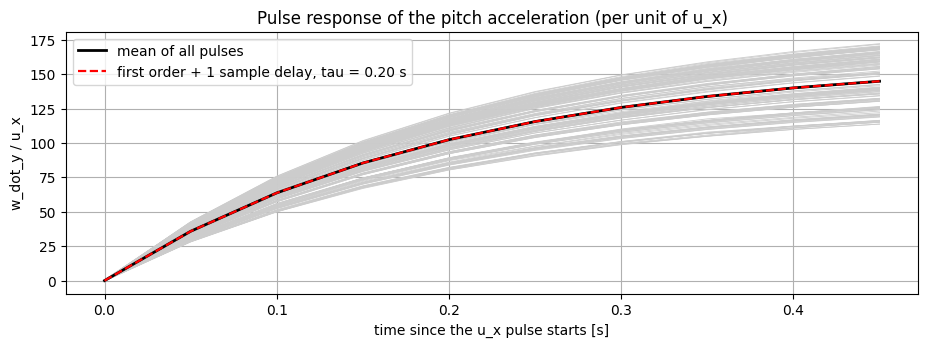

In [7]:
def pulse_responses(min_len=10, n_win=10):
    out, uts = [], []
    for i in range(n_exp):
        starts = np.flatnonzero((UX[i, 1:] != 0) & (UX[i, :-1] == 0)) + 1
        for a in starts:
            if a + n_win > n_t or not quiet[i, a - 1]:
                continue
            seg = UX[i, a:a + n_win]
            if np.all(seg == seg[0]) and np.ptp(UT[i, a - 1:a + n_win]) == 0 and abs(seg[0]) > 1e-3:
                out.append((W[i, a:a + n_win] - W[i, a - 1]) / seg[0]); uts.append(UT[i, a])
    return np.array(out), np.array(uts)

R, R_uT = pulse_responses()
mean = R.mean(axis=0)
tt = np.arange(len(mean)) * Ts
best = (np.inf, None, None)
for tau in np.arange(0.05, 0.6, 0.005):
    shape = np.where(tt >= Ts, 1 - np.exp(-tt / tau), 0.0)
    K = shape @ mean / (shape @ shape)
    err = np.sum((mean - K * shape) ** 2)
    if err < best[0]:
        best = (err, tau, K)
_, tau_x, K_pulse = best
print(f'{len(R)} pulses collected (u_T median {np.median(R_uT):.2f})')
print(f'mean response at samples 0, 1, 2: {mean[:3].round(2)}   (0 at sample 0 = one sample of delay)')
print(f'first order + 1 sample delay: tau = {tau_x:.3f} s (altitude 0.196 s), K = {K_pulse:.1f} rad/s^2 per unit of u_x')

plt.figure(figsize=(11, 3.4))
plt.plot(tt, R[:150].T, color='0.8', lw=.6)
plt.plot(tt, mean, 'k', lw=2, label='mean of all pulses')
plt.plot(tt, K_pulse * np.where(tt >= Ts, 1 - np.exp(-tt / tau_x), 0), 'r--', lw=1.6,
         label=f'first order + 1 sample delay, tau = {tau_x:.2f} s')
plt.xlabel('time since the u_x pulse starts [s]'); plt.ylabel('w_dot_y / u_x'); plt.legend()
plt.title('Pulse response of the pitch acceleration (per unit of u_x)'); plt.show()

## 4. Physics around the identified link

Two questions decide what the model must contain.

**Does the drone produce a pitch torque by itself?** In the quiet stretches the commands give no
torque. If `w_dot_y` there depends on the tilt (pendulum effect), on `wy` (rotational damping) or on
`vx` (aerodynamic moment), these must be inputs of the model. We regress it on all three and compare
the worst case over the flight envelope of the mission with the torque of a small command: the
noise floor is not the right yardstick, the last percent of the motor lag is still there after 20
samples.

**The tilted thrust.** The thrust is along the drone's axis: its vertical part gives $a_z + g$ and its
horizontal part $a_x$, so $a_x = \pm (a_z + g)\tan\theta$. We fit $a_x = c_1 (a_z + g)\tan\theta +
c_2 v_x + c_0$: $|c_1| \approx 1$ confirms the law (its sign is the frame convention), $c_2$ is the
linear drag along x.

quiet stretches: w_dot_y = -0.0287 theta -0.0419 wy +0.00045 vx -0.0000
  over theta in [-0.55, 0.56] rad, wy in [-0.05, 0.07], vx in [-30.9, 59.2] m/s
  worst case over the envelope {'theta': 0.3, 'wy': 0.5, 'vx': 2.0}: 0.0304 rad/s^2 = 1.9 % of the torque of u_x = 0.01
  -> negligible: the drone is a pure chain of integrators

tilted thrust: ax = +0.9962 (az+g) tan(theta) -0.00128 vx -0.0001
  rms residual 0.0177 m/s^2   (ax std 1.150)


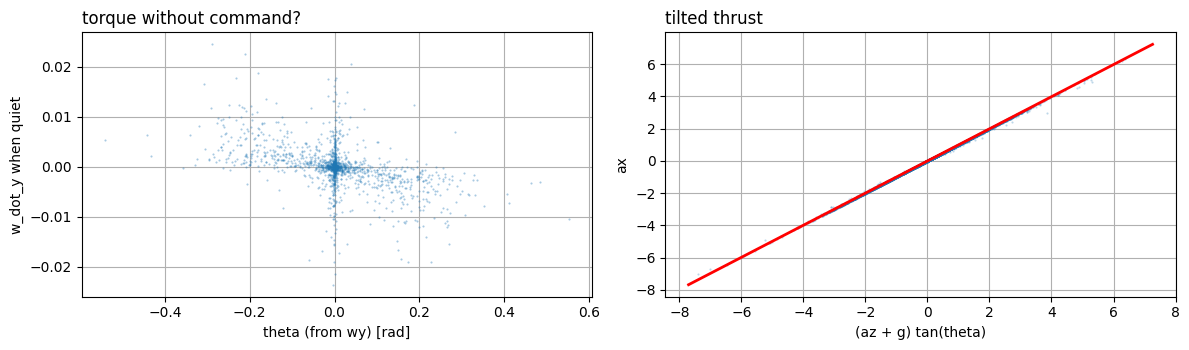

In [8]:
q = quiet & (np.arange(n_t) > N_REST)
A_q = np.column_stack([TH[q], WY[q], VX[q], np.ones(q.sum())])
coef_q, *_ = np.linalg.lstsq(A_q, W[q], rcond=None)
print('quiet stretches: w_dot_y = '
      f'{coef_q[0]:+.4f} theta {coef_q[1]:+.4f} wy {coef_q[2]:+.5f} vx {coef_q[3]:+.4f}')
print(f'  over theta in [{TH[q].min():.2f}, {TH[q].max():.2f}] rad, wy in [{WY[q].min():.2f}, {WY[q].max():.2f}], '
      f'vx in [{VX[q].min():.1f}, {VX[q].max():.1f}] m/s')
# compared with what the command can do: worst case over the flight envelope of the mission
ENVELOPE = {'theta': 0.3, 'wy': 0.5, 'vx': 2.0}
self_torque = sum(abs(c) * v for c, v in zip(coef_q[:3], ENVELOPE.values()))
ratio = self_torque / (K_pulse * 0.01)
print(f'  worst case over the envelope {ENVELOPE}: {self_torque:.4f} rad/s^2'
      f' = {100 * ratio:.1f} % of the torque of u_x = 0.01'
      f'\n  -> {"negligible: the drone is a pure chain of integrators" if ratio < 0.05 else "NOT NEGLIGIBLE: add theta / wy / vx as inputs of the model"}')

m = np.arange(n_t) > N_REST
m = np.broadcast_to(m, AX.shape) & (UT > 0)
tan_term = (AZ + G) * np.tan(TH)
A_ax = np.column_stack([tan_term[m], VX[m], np.ones(m.sum())])
coef_ax, *_ = np.linalg.lstsq(A_ax, AX[m], rcond=None)
res_ax = AX[m] - A_ax @ coef_ax
print(f'\ntilted thrust: ax = {coef_ax[0]:+.4f} (az+g) tan(theta) {coef_ax[1]:+.5f} vx {coef_ax[2]:+.4f}')
print(f'  rms residual {res_ax.std():.4f} m/s^2   (ax std {AX[m].std():.3f})')
C_AX = float(np.round(coef_ax[0]))         # the frame convention (+1 or -1)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(TH[q][::10], W[q][::10], '.', ms=1, alpha=.4); ax[0].set_xlabel('theta (from wy) [rad]')
ax[0].set_ylabel('w_dot_y when quiet'); ax[0].set_title('torque without command?', loc='left')
ax[1].plot(tan_term[m][::20], AX[m][::20], '.', ms=1, alpha=.3)
g_ = np.linspace(tan_term[m].min(), tan_term[m].max(), 2); ax[1].plot(g_, coef_ax[0] * g_, 'r', lw=2)
ax[1].set_xlabel('(az + g) tan(theta)'); ax[1].set_ylabel('ax'); ax[1].set_title('tilted thrust', loc='left')
plt.tight_layout(); plt.show()

## 5. Identification by least squares

Same discrete first-order model with one sample of delay as for the yaw:

$$\dot w_y[k+1] \;=\; a\,\dot w_y[k] \;+\; \sum_j b_j\,g_j\big(u_T[k],\,u_x[k]\big) \;+\; c$$

| model | $g_j$ | idea |
|---|---|---|
| **A** linear | $u_x$ | constant gain: ignores the thrust |
| **B** polynomial gain | $u_x,\ u_x u_T,\ u_x u_T^2$ | the gain is a smooth function of $u_T$ |
| **C** physical | $\tanh(\beta(u_T+u_x)) - \tanh(\beta(u_T-u_x))$ | motors 1 and 3 are the saturating actuators of notebook 1; the torque is their difference |

$\beta$ of model C by separable least squares on the training experiments; the pole $a$ gives back the
time constant, $\tau = -T_s / \ln a$, to compare with section 3; $c \approx 0$.

286 experiments for identification, 96 held out for validation


best beta = 1.00   (altitude model of notebook 1: 0.90)


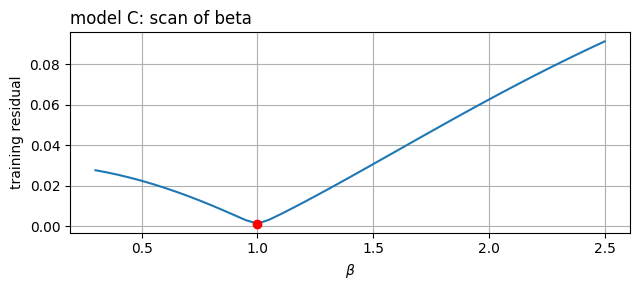

In [9]:
rng = np.random.default_rng(SEED)
split = int(0.75 * n_exp)
train, test = np.arange(split), np.arange(split, n_exp)
print(f'{len(train)} experiments for identification, {len(test)} held out for validation')

def design(rows, basis):
    Xd, y = [], []
    for i in rows:
        uT, ux, w0, w1 = UT[i, :-1], UX[i, :-1], W[i, :-1], W[i, 1:]
        Xd.append(np.column_stack([w0] + [g(uT, ux) for g in basis] + [np.ones_like(ux)]))
        y.append(w1)
    return np.vstack(Xd), np.concatenate(y)

def identify(basis, rows=None):
    Xd, y = design(train if rows is None else rows, basis)
    return np.linalg.lstsq(Xd, y, rcond=None)[0]

def tanh_basis(beta):
    return [lambda uT, ux, b=beta: np.tanh(b * (uT + ux)) - np.tanh(b * (uT - ux))]

scan_rows = train[:min(len(train), 200)]
betas = np.arange(0.3, 2.51, 0.05)
err_b = []
for bt in betas:
    Xd, y = design(scan_rows, tanh_basis(bt))
    err_b.append((y - Xd @ identify(tanh_basis(bt), scan_rows)).std())
beta_opt = betas[int(np.argmin(err_b))]
print(f'best beta = {beta_opt:.2f}   (altitude model of notebook 1: 0.90)')

plt.figure(figsize=(6.5, 3)); plt.plot(betas, err_b); plt.plot(beta_opt, min(err_b), 'ro')
plt.xlabel(r'$\beta$'); plt.ylabel('training residual'); plt.title('model C: scan of beta', loc='left')
plt.tight_layout(); plt.show()

In [10]:
BASES = {
    'A  linear        ': [lambda uT, ux: ux],
    'B  poly gain     ': [lambda uT, ux: ux, lambda uT, ux: ux * uT, lambda uT, ux: ux * uT ** 2],
    'C  tanh (physics)': tanh_basis(beta_opt),
}
theta = {name: identify(b) for name, b in BASES.items()}
for name, th in theta.items():
    print(f'{name}  theta = {np.round(th, 4)}')
    print(f'{"":19s} tau = {-Ts / np.log(th[0]):.3f} s  (pulse response: {tau_x:.3f} s)   c = {th[-1]:+.4f} (expect ~0)')

thB = theta['B  poly gain     ']
uT_g = np.linspace(0.2, 0.7, 6)
print('\nstatic gain d(w_dot_y)/d(u_x) at u_x = 0 (model B):',
      ', '.join(f'u_T={u:.1f}: {(thB[1] + thB[2] * u + thB[3] * u ** 2) / (1 - thB[0]):.0f}' for u in uT_g))

A  linear          theta = [ 0.7798 36.2598 -0.    ]
                    tau = 0.201 s  (pulse response: 0.200 s)   c = -0.0000 (expect ~0)
B  poly gain       theta = [  0.7786  46.1263 -13.6727 -17.618    0.    ]
                    tau = 0.200 s  (pulse response: 0.200 s)   c = +0.0000 (expect ~0)
C  tanh (physics)  theta = [ 0.7786 22.1419  0.    ]
                    tau = 0.200 s  (pulse response: 0.200 s)   c = +0.0000 (expect ~0)

static gain d(w_dot_y)/d(u_x) at u_x = 0 (model B): u_T=0.2: 193, u_T=0.3: 183, u_T=0.4: 171, u_T=0.5: 158, u_T=0.6: 143, u_T=0.7: 126


## 6. The neural network

$$\dot w_y[k+1] = F\big(\dot w_y[k],\ u_x[k],\ u_T[k]\big)$$

Same recipe as notebook 4 (one hidden layer of 16 tanh units, standardised inputs and output, Adam,
early stopping), with a smaller stopping tolerance (`tol = 1e-6`): the pitch data is far less noisy
than the yaw data, and with the default tolerance the training stopped after ~20 epochs, 3x worse than
model C in free run. If section 4 found a torque without command, its inputs (`theta`, `wy`, `vx`) go into
`dataset()` as extra columns.

The honest test is the **free run**: the model gets only the two commands and feeds back its own output
for the whole experiment.

In [11]:
def dataset(rows):
    Xd = np.concatenate([np.column_stack([W[i, :-1], UX[i, :-1], UT[i, :-1]]) for i in rows])
    y = np.concatenate([W[i, 1:] for i in rows])
    return Xd, y

X_tr, y_tr = dataset(train)
if len(y_tr) > N_TRAIN_MAX:
    idx = rng.choice(len(y_tr), N_TRAIN_MAX, replace=False)
    X_tr, y_tr = X_tr[idx], y_tr[idx]
X_te, y_te = dataset(test)

sx = StandardScaler().fit(X_tr)
sy = StandardScaler().fit(y_tr.reshape(-1, 1))
net = MLPRegressor(hidden_layer_sizes=(16,), activation='tanh', solver='adam', learning_rate_init=1e-3,
                   batch_size=256, max_iter=200, tol=1e-6, early_stopping=True, n_iter_no_change=10,
                   validation_fraction=0.15, random_state=SEED)
net.fit(sx.transform(X_tr), sy.transform(y_tr.reshape(-1, 1)).ravel())
n_par = sum(c.size for c in net.coefs_) + sum(b.size for b in net.intercepts_)
print(f'{len(y_tr):,} training samples; stopped after {net.n_iter_} epochs, {n_par} parameters')

def predict(Xd):
    return sy.inverse_transform(net.predict(sx.transform(Xd)).reshape(-1, 1)).ravel()

171,314 training samples; stopped after 70 epochs, 81 parameters


In [12]:
def free_run_nn(rows):
    w = np.zeros((len(rows), n_t)); w[:, 0] = W[rows, 0]
    for k in range(n_t - 1):
        w[:, k + 1] = predict(np.column_stack([w[:, k], UX[rows, k], UT[rows, k]]))
    return w

def free_run_ls(th, basis, rows):
    a, b, c = th[0], th[1:-1], th[-1]
    w = np.zeros((len(rows), n_t)); w[:, 0] = W[rows, 0]
    for k in range(n_t - 1):
        uT, ux = UT[rows, k], UX[rows, k]
        w[:, k + 1] = a * w[:, k] + sum(bj * g(uT, ux) for bj, g in zip(b, basis)) + c
    return w

sub = test[:100]
rmse = lambda p, rows: float(np.sqrt(np.mean((p - W[rows]) ** 2)))
print(f'{"model":19s} {"params":>7s} {"one-step":>10s} {"free-run":>10s}   [rad/s^2]')
free = {}
for name, basis in BASES.items():
    Xd, y = design(test, basis)
    free[name] = free_run_ls(theta[name], basis, sub)
    print(f'{name:19s} {len(theta[name]):7d} {(y - Xd @ theta[name]).std():10.4f} {rmse(free[name], sub):10.4f}')
free['NN'] = free_run_nn(sub)
print(f'{"neural network":19s} {n_par:7d} {np.sqrt(np.mean((predict(X_te) - y_te) ** 2)):10.4f} {rmse(free["NN"], sub):10.4f}')
print(f'{"measurement noise":19s} {"":7s} {noise_std:10.4f}')

model                params   one-step   free-run   [rad/s^2]
A  linear                 3     0.0244     0.0536
B  poly gain              5     0.0016     0.0032
C  tanh (physics)         3     0.0015     0.0031


neural network           81     0.0018     0.0041
measurement noise               0.0009


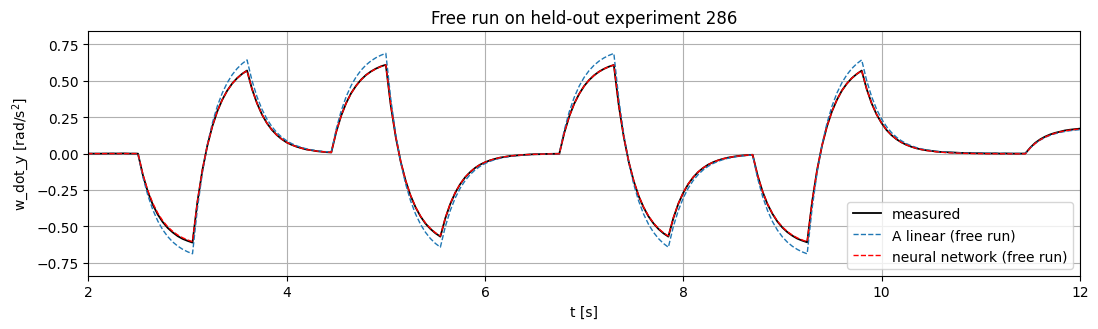

In [13]:
i = 0
plt.figure(figsize=(11, 3.4))
plt.plot(t, W[sub[i]], 'k', lw=1.3, label='measured')
plt.plot(t, free['A  linear        '][i], '--', lw=1, label='A linear (free run)')
plt.plot(t, free['NN'][i], 'r--', lw=1, label='neural network (free run)')
plt.xlim(2, 12); plt.xlabel('t [s]'); plt.ylabel('w_dot_y [rad/s$^2$]'); plt.legend()
plt.title(f'Free run on held-out experiment {sub[i]}'); plt.tight_layout(); plt.show()

### What did the network learn?

The static characteristic is the fixed point of $\dot w_y = F(\dot w_y, u_x, u_T)$ for constant
commands. The pulses are too short to settle in the data, so we compare it with the static
characteristic of the physical model C, $K\,[\tanh(\beta(u_T+u_x)) - \tanh(\beta(u_T-u_x))]$: two
independent fits should agree, including the drop of gain with the thrust.

**Range of validity.** The two agree for $|u_x| \lesssim 0.02$. Beyond, the curves part: to respect the
tilt bound of the design, pulses stronger than 0.02 last only 3 to 4 samples in the data and never
settle, so the fixed point there is an extrapolation of the network (model C extrapolates its
tanh instead). The RL environment therefore limits the action to $|u_x| \le 0.02$, which already
tilts the drone by 0.3 rad in 0.5 s.

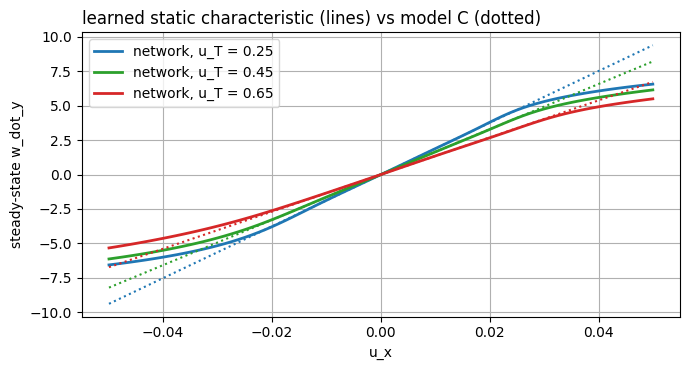

In [14]:
thC = theta['C  tanh (physics)']
K_C, c0_C = thC[1] / (1 - thC[0]), thC[2] / (1 - thC[0])
ux_grid = np.linspace(UX.min(), UX.max(), 81)
plt.figure(figsize=(7, 3.8))
for uT0, c in zip((0.25, 0.45, 0.65), ('tab:blue', 'tab:green', 'tab:red')):
    w = np.zeros_like(ux_grid)
    for _ in range(200):
        w = predict(np.column_stack([w, ux_grid, np.full_like(ux_grid, uT0)]))
    plt.plot(ux_grid, K_C * (np.tanh(beta_opt * (uT0 + ux_grid)) - np.tanh(beta_opt * (uT0 - ux_grid))) + c0_C,
             ':', color=c, lw=1.5)
    plt.plot(ux_grid, w, color=c, lw=2, label=f'network, u_T = {uT0}')
plt.xlabel('u_x'); plt.ylabel('steady-state w_dot_y'); plt.legend()
plt.title('learned static characteristic (lines) vs model C (dotted)', loc='left'); plt.tight_layout(); plt.show()

## 7. What matters for control: the position over the duration of a move

The controller acts on `x`, the **fourth** integral of `w_dot_y` (through `wy`, `theta`, `ax`, `vx`).
Over a whole experiment any model error accumulates without bound, so we look at the horizon of one
manoeuvre: start the model from the **measured** state at random instants, simulate **2 s** with the
true commands, and compare the predicted position with the measured one. The thrust term uses the
measured `az` (the altitude has its own model): this isolates the error of the x chain, which the
RL policy will have to absorb when it moves from the model to the simulator.

In [15]:
H = 40                                      # 2 s horizon
starts = [(i, k) for i in sub for k in rng.integers(N_REST, n_t - H, 20)]
def position_error(step_fn):
    errs = []
    for i, k in starts:
        w, wy, th, vx, x = W[i, k], WY[i, k], TH[i, k], VX[i, k], X[i, k]
        ax = C_AX * (AZ[i, k] + G) * np.tan(th) + coef_ax[1] * vx
        for j in range(H):
            w1 = step_fn(w, UX[i, k + j], UT[i, k + j])
            wy1 = wy + Ts * (w + w1) / 2
            th1 = th + Ts * (wy + wy1) / 2
            ax1 = C_AX * (AZ[i, k + j + 1] + G) * np.tan(th1) + coef_ax[1] * vx
            vx1 = vx + Ts * (ax + ax1) / 2
            x += Ts * (vx + vx1) / 2
            w, wy, th, ax, vx = w1, wy1, th1, ax1, vx1
        errs.append(x - X[i, k + H])
    return np.abs(np.array(errs))

nn_step = lambda w, ux, uT: float(predict(np.array([[w, ux, uT]]))[0])
thA = theta['A  linear        ']
A_step = lambda w, ux, uT: thA[0] * w + thA[1] * ux + thA[2]
C_step = lambda w, ux, uT: thC[0] * w + thC[1] * (np.tanh(beta_opt * (uT + ux)) - np.tanh(beta_opt * (uT - ux))) + thC[2]
print(f'position error after {H * Ts:.0f} s, over {len(starts)} random starts   (median / 90th percentile)')
for name, f in (('A linear', A_step), ('C tanh', C_step), ('neural network', nn_step)):
    e = position_error(f)
    print(f'  {name:15s}: {100 * np.median(e):6.2f} cm / {100 * np.percentile(e, 90):6.2f} cm')

position error after 2 s, over 1920 random starts   (median / 90th percentile)


  A linear       :   4.30 cm /  25.13 cm


  C tanh         :   0.89 cm /   2.74 cm


  neural network :   1.20 cm /   3.25 cm


## 8. Coupling: does the motion along x disturb the altitude and the heading?

The plan keeps the **altitude and yaw policies unchanged** and adds an x policy next to them, as was
done for the yaw. Two couplings are expected:

* **altitude**: a tilted thrust lifts less, $a_z + g = T\cos\theta$, so the vertical acceleration loses
  about $g\,\theta^2/2$ (0.2 m/s^2 at 0.2 rad), plus a small saturation loss $\propto u_x^2$. We run
  the altitude NN of notebook 2 (which knows only `u_T`) in free run and fit its residual;
* **heading**: motors 1 and 3 turn in the same direction; with saturating motors their torques do not
  cancel exactly, $\dot w_z \propto u_x^2$ (seen while designing the excitation).

az residual of the altitude model (u_T only): rms 0.136 m/s^2
fit  az_residual = -5.13 theta^2 -12.4 u_x^2 +0.047   (tilt law: -g/2 = -4.91)  ->  at theta = 0.2 rad: -0.205 m/s^2
(the altitude policy was trained with hover offsets up to +/- 0.4 m/s^2)

heading: w_dot_z = -3.79 u_x^2 -0.00018  ->  at u_x = 0.01: -0.00038 rad/s^2  (yaw authority: ~150 rad/s^2 per unit of u_yaw)


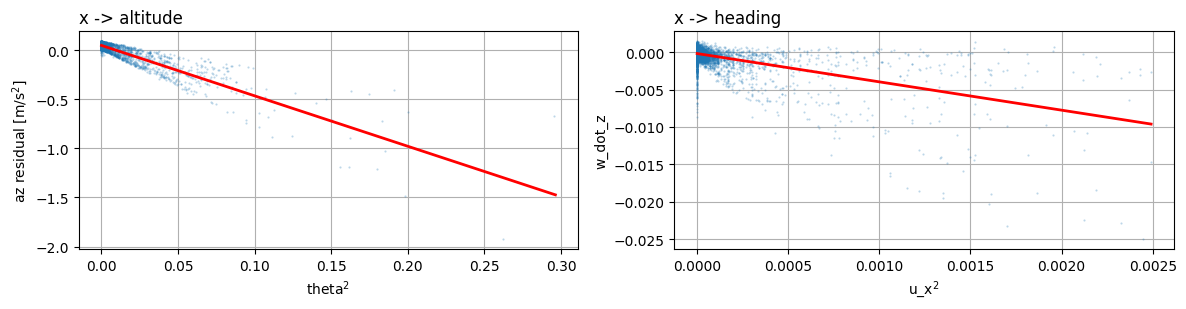

In [16]:
alt = joblib.load(os.path.join('models', 'drone_model_nn.joblib'))
def az_free_run(rows):
    az = np.zeros((len(rows), n_t)); az[:, 0] = AZ[rows, 0]
    for k in range(n_t - 1):
        xin = alt['sx'].transform(np.column_stack([az[:, k], UT[rows, k]]))
        az[:, k + 1] = alt['sy'].inverse_transform(alt['net'].predict(xin).reshape(-1, 1)).ravel()
    return az

az_hat = az_free_run(sub)
r_az = (AZ[sub] - az_hat)[:, N_REST:].ravel()
th2, ux2 = (TH[sub][:, N_REST:] ** 2).ravel(), (UX[sub][:, N_REST:] ** 2).ravel()
c_az, *_ = np.linalg.lstsq(np.column_stack([th2, ux2, np.ones_like(th2)]), r_az, rcond=None)
print(f'az residual of the altitude model (u_T only): rms {r_az.std():.3f} m/s^2')
print(f'fit  az_residual = {c_az[0]:.2f} theta^2 {c_az[1]:+.1f} u_x^2 {c_az[2]:+.3f}'
      f'   (tilt law: -g/2 = {-G / 2:.2f})  ->  at theta = 0.2 rad: {c_az[0] * 0.04:+.3f} m/s^2')
print('(the altitude policy was trained with hover offsets up to +/- 0.4 m/s^2)')

wdz = WDZ[:, N_REST:].ravel(); u2 = (UX[:, N_REST:] ** 2).ravel()
k_yaw = np.polyfit(u2, wdz, 1)
print(f'\nheading: w_dot_z = {k_yaw[0]:+.2f} u_x^2 {k_yaw[1]:+.5f}  ->  at u_x = 0.01: {k_yaw[0] * 1e-4:+.5f} rad/s^2'
      f'  (yaw authority: ~150 rad/s^2 per unit of u_yaw)')

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
ax[0].plot(th2[::20], r_az[::20], '.', ms=1, alpha=.3)
g_ = np.linspace(0, th2.max(), 50); ax[0].plot(g_, c_az[0] * g_ + c_az[2], 'r', lw=2)
ax[0].set_xlabel('theta$^2$'); ax[0].set_ylabel('az residual [m/s$^2$]'); ax[0].set_title('x -> altitude', loc='left')
ax[1].plot(u2[::20], wdz[::20], '.', ms=1, alpha=.3)
g_ = np.linspace(0, u2.max(), 50); ax[1].plot(g_, np.polyval(k_yaw, g_), 'r', lw=2)
ax[1].set_xlabel('u_x$^2$'); ax[1].set_ylabel('w_dot_z'); ax[1].set_title('x -> heading', loc='left')
plt.tight_layout(); plt.show()

## 9. Save the model for the RL environment

Same contract as `models/yaw_model_nn.joblib`. Saved with it: the mixer `S_X`, the time constant, the
coefficients of model C (for a cascade PD baseline with feedback linearisation) and of the tilted-thrust
law `ax = C_AX (az + g) tan(theta) + c_drag vx`.

In [17]:
joblib.dump({'net': net, 'sx': sx, 'sy': sy, 'Ts': Ts,
             'inputs': ('w_dot_y[k]', 'u_x[k]', 'u_T[k]'), 'output': 'w_dot_y[k+1]',
             'S_X': S_X, 'tau': float(tau_x), 'x_max_data': float(np.abs(UX).max()),
             'uT_data': (float(UT[:, N_REST:].min()), float(UT.max())),
             'theta_C': theta['C  tanh (physics)'], 'beta_C': float(beta_opt),
             'C_AX': C_AX, 'c_drag': float(coef_ax[1]), 'k_az_tilt': float(c_az[0]), 'k_yaw_ux2': float(k_yaw[0])},
            os.path.join('models', 'x_model_nn.joblib'))
print('saved models/x_model_nn.joblib')
print('check: commands at rest (u_x = 0) ->', round(float(predict(np.array([[0.0, 0.0, 0.39]]))[0]), 4), 'rad/s^2 (expect ~0)')

saved models/x_model_nn.joblib
check: commands at rest (u_x = 0) -> -0.0005 rad/s^2 (expect ~0)


## 10. Conclusions (to write once the notebook has run on the full dataset)

1. **Dataset**: how many experiments were dropped, and why? Is `phi` at 0 (pure pitch)? Is the chain
   `w_dot_y -> wy -> ... -> x` made of trapezoid integrals (section 2)?
2. **Order and delay**: first order with the motors' 0.2 s and one sample of delay (section 3)?
3. **Physics**: no torque without command (no restoring torque, no damping) means the open-loop drone
   is a chain of **four integrators**: it never comes back level by itself, the controller must do it.
   Does `ax = (az + g) tan(theta)` hold, is there drag along x (section 4)?
4. **Models**: model C vs B, $\beta$ vs the 0.9 of the altitude; the network vs the noise floor in free
   run (sections 5-6).
5. **For the controller**: the position error over 2 s (section 7) is the model-to-simulator gap; the
   couplings of section 8 say whether the altitude and yaw policies can be kept unchanged.